In [1]:
import json
import os
from pathlib import Path
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from scipy import stats

# Run notebook from analysis/ or set explicitly; path relative to cwd
RESULTS_DIR = (Path("..") / "results").resolve()

# Map full model paths to simplified names (like configs: dinov2_14, clip_16, etc.)
def simplify_model_name(full_name):
    """Convert e.g. facebook/dinov2-base -> dinov2_14, openai/clip-vit-base-patch32 -> clip_32"""
    m = full_name.lower()
    if "dinov2" in m or "dinov2-base" in m:
        return "DINOv2"
    if "dino-vitb" in m:
        return "DINO"
    if "vit-mae" in m or "mae" in m:
        return "MAE"
    if "google" in m:
        if "patch32" in m or "patch 32" in m:
            return "Imagenet 32"
        return "Imagenet 16"
    if "clip" in m:
        if "patch32" in m or "patch 32" in m:
            return "CLIP 32"
        return "CLIP 16"
    return full_name.replace("/", "_")


def load_gestalt_results(results_dir=None):
    """
    Load all gestalt_eval.json files from the results directory.
    Returns: dict[model_name, dict[layer, results_dict]]
    """
    results_dir = Path(results_dir or RESULTS_DIR)
    data = defaultdict(dict)
    
    for org_dir in Path(results_dir).iterdir():
        if not org_dir.is_dir():
            continue
        for model_dir in org_dir.iterdir():
            if not model_dir.is_dir():
                continue
            model_name = f"{org_dir.name}/{model_dir.name}"
            for layer_dir in model_dir.iterdir():
                if not layer_dir.is_dir():
                    continue
                try:
                    layer = int(layer_dir.name)
                except ValueError:
                    continue
                json_path = layer_dir / "gestalt_eval.json"
                if json_path.exists():
                    with open(json_path, "r") as f:
                        data[model_name][layer] = json.load(f)
    
    return dict(data)


def plot_per_layer_accuracy(data=None, results_dir=None, models=None, subplots_per_model=True, ax=None):
    """
    Plot per-layer test accuracy for each model, compared to orientation and location accuracies.
    
    For each model: x=layer, y=accuracy; lines for base (test), orientation, location.
    subplots_per_model: if True, one subplot per model; else all models on one plot.
    """
    data = data or load_gestalt_results(results_dir)
    if models:
        data = {m: data[m] for m in models if m in data}
    
    model_list = sorted(data.items())
    n = len(model_list)
    
    if subplots_per_model and n > 1:
        ncols = min(n, 3)
        nrows = (n + ncols - 1) // ncols
        fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows), squeeze=False)
        axes = axes.flatten()
        for idx in range(n, len(axes)):
            axes[idx].set_visible(False)
    else:
        if ax is not None:
            fig = ax.figure
            axes = [ax]
        else:
            fig, ax = plt.subplots(figsize=(10, 6))
            axes = [ax]
    
    for idx, (model_name, layer_results) in enumerate(model_list):
        a = axes[idx] if subplots_per_model and n > 1 else axes[0]
        layers = sorted(layer_results.keys())
        base_acc = [layer_results[l]["standard"]["base"]["accuracy"] for l in layers]
        orient_acc = [layer_results[l]["standard"]["orientation"]["accuracy"] for l in layers]
        loc_acc = [layer_results[l]["standard"]["location"]["accuracy"] for l in layers]
        
        suff = f" ({model_name})" if not (subplots_per_model and n > 1) else ""
        a.plot(layers, base_acc, "o-", label=f"Test/base{suff}", linewidth=2, markersize=6)
        a.plot(layers, orient_acc, "s--", label=f"Orientation{suff}", alpha=0.8, markersize=4)
        a.plot(layers, loc_acc, "^-.", label=f"Location{suff}", alpha=0.8, markersize=4)
        
        a.set_xlabel("Layer")
        a.set_ylabel("Accuracy")
        if subplots_per_model and n > 1:
            short_name = simplify_model_name(model_name)
            a.set_title(short_name)
        else:
            a.set_title("Per-layer probe accuracy vs. orientation and location controls")
        a.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
        a.grid(True, alpha=0.3)
        a.axhline(0.5, color="gray", linestyle=":", alpha=0.5)
    
    plt.tight_layout()
    return axes[0] if len(axes) == 1 else axes


def plot_ablation_decrement_by_layer(data=None, results_dir=None, models=None, control_band="iqr", normalize_by="max", ax=None):
    """
    One subplot per model. X=layer, Y=ablation decrement (optionally normalized).
    Control band is dynamic per (model, layer): shows distribution of control decrements at that layer.
    control_band: "std", "iqr", or "minmax"
    normalize_by: "max" | "mean" | None. If set, y is divided by (base - max/mean of location, orientation) for that layer.
    """
    data = data or load_gestalt_results(results_dir)
    if models:
        data = {m: data[m] for m in models if m in data}

    model_list = sorted(data.items())
    n = len(model_list)
    ncols = min(n, 3)
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows), squeeze=False)
    axes = axes.flatten()
    for idx in range(n, len(axes)):
        axes[idx].set_visible(False)

    for idx, (model_name, layer_results) in enumerate(model_list):
        ax = axes[idx]
        short_name = simplify_model_name(model_name)
        layers = sorted(layer_results.keys())
        decs = []
        control_lower, control_upper = [], []

        for l in layers:
            res = layer_results[l]
            base = res["standard"]["base"]["accuracy"]
            orient = res["standard"]["orientation"]["accuracy"]
            loc = res["standard"]["location"]["accuracy"]
            abl = res["ablation"]["base"]["accuracy"]
            dec = base - abl

            if normalize_by == "max":
                denom = base - max(orient, loc)
            elif normalize_by == "mean":
                denom = base - (orient + loc) / 2
            else:
                denom = 1.0

            denom = max(denom, 1e-6)
            dec_norm = dec / denom
            decs.append(dec_norm)

            ctrl_decs = [base - c for c in res["controls"]["base"]["accuracy"]]
            if control_band == "std":
                m, s = np.mean(ctrl_decs), np.std(ctrl_decs)
                lo, hi = (m - s) / denom, (m + s) / denom
            elif control_band == "iqr":
                q25, q75 = np.percentile(ctrl_decs, [25, 75])
                lo, hi = q25 / denom, q75 / denom
            else:
                lo, hi = np.min(ctrl_decs) / denom, np.max(ctrl_decs) / denom
            control_lower.append(lo)
            control_upper.append(hi)

        ax.fill_between(layers, control_lower, control_upper, alpha=0.2, color="gray", label="Control ablations")
        ax.plot(layers, decs, "o-", color="C0", linewidth=2, markersize=6, label="Target ablation")
        ax.set_xlabel("Layer")
        ylabel = "Ablation decrement"
        if normalize_by:
            ylabel += f" / (base − {normalize_by}(loc, orient))"
        ax.set_ylabel(ylabel)
        ax.set_title(short_name)
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)
        ax.axhline(0, color="gray", linestyle=":", alpha=0.5)

    plt.tight_layout()
    return axes

In [3]:
# Example usage:
from typing import Any

results_path = Path("/home/alexart/gestalt-interp/binding_probes/results")

data = load_gestalt_results(results_path)
print("Models:", list[Any](data.keys()))
print("Layers per model:", {m: sorted(d.keys()) for m, d in data.items()})

Models: ['google/vit-base-patch32-224-in21k', 'google/vit-base-patch16-224-in21k', 'openai/clip-vit-base-patch32', 'openai/clip-vit-base-patch16', 'facebook/vit-mae-base', 'facebook/dino-vitb16', 'facebook/dinov2-base']
Layers per model: {'google/vit-base-patch32-224-in21k': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'google/vit-base-patch16-224-in21k': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'openai/clip-vit-base-patch32': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'openai/clip-vit-base-patch16': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'facebook/vit-mae-base': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'facebook/dino-vitb16': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], 'facebook/dinov2-base': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]}


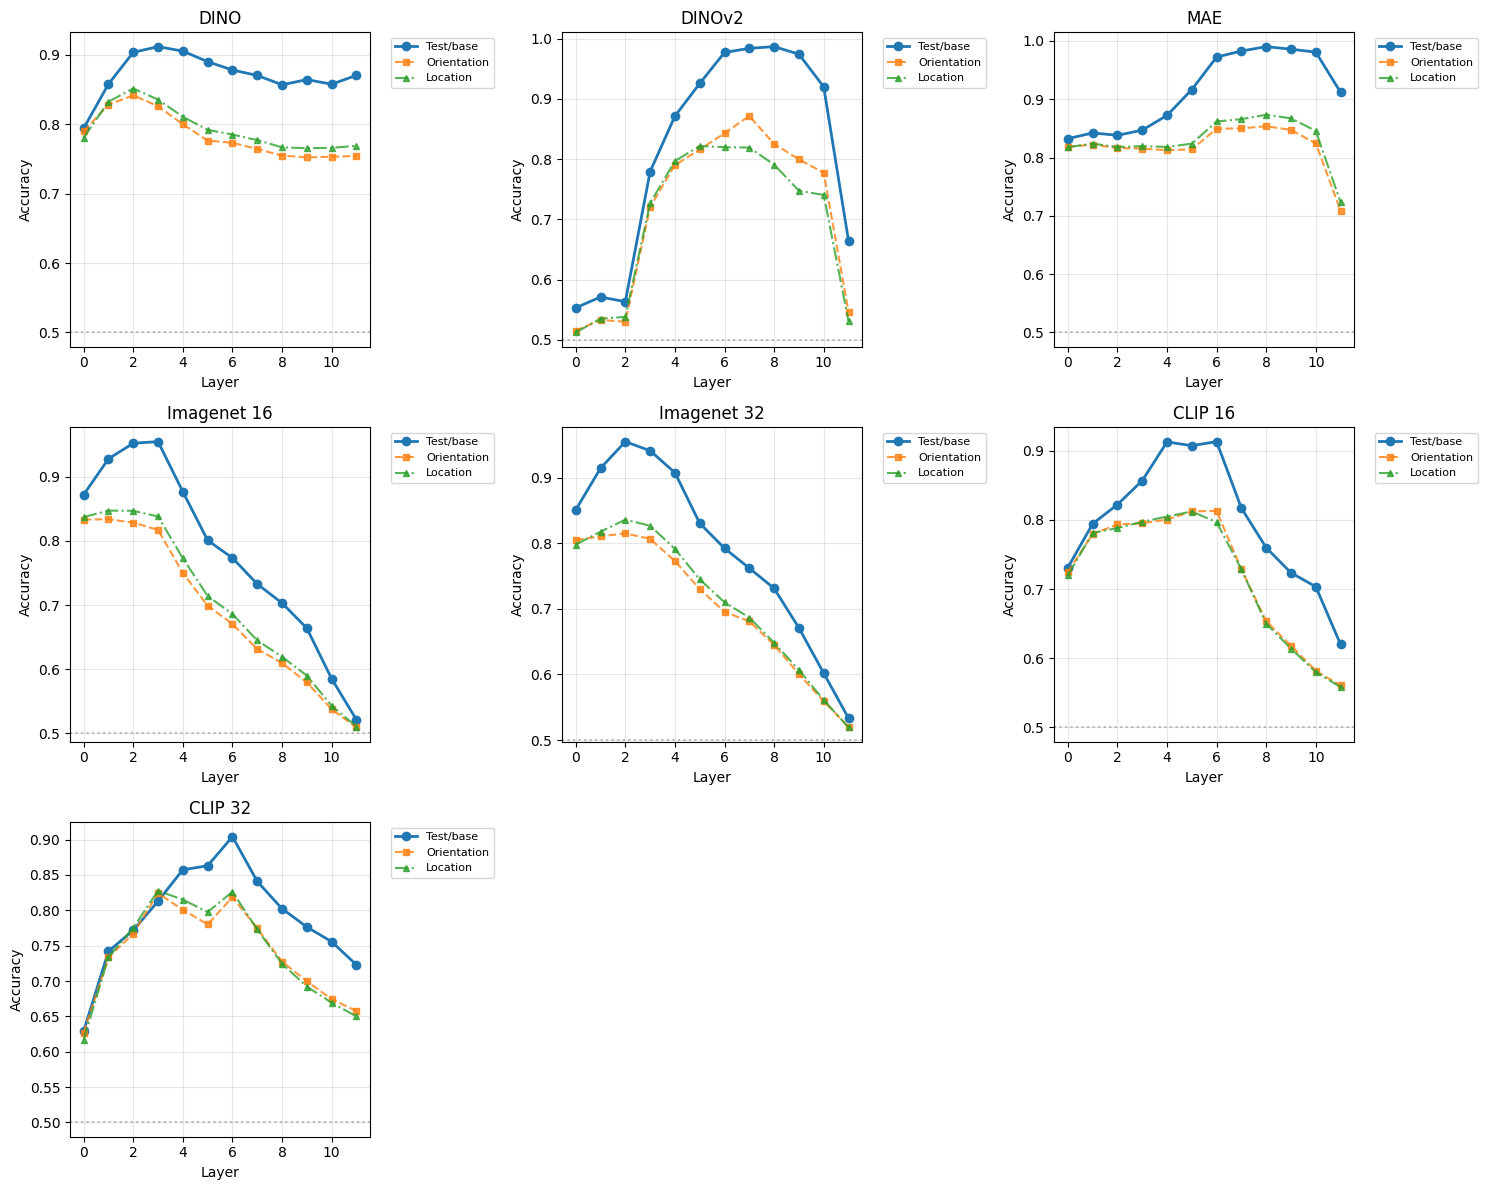

In [4]:
# Plot 1: Per-layer test accuracy vs orientation and location
plot_per_layer_accuracy(data=data)
plt.show()

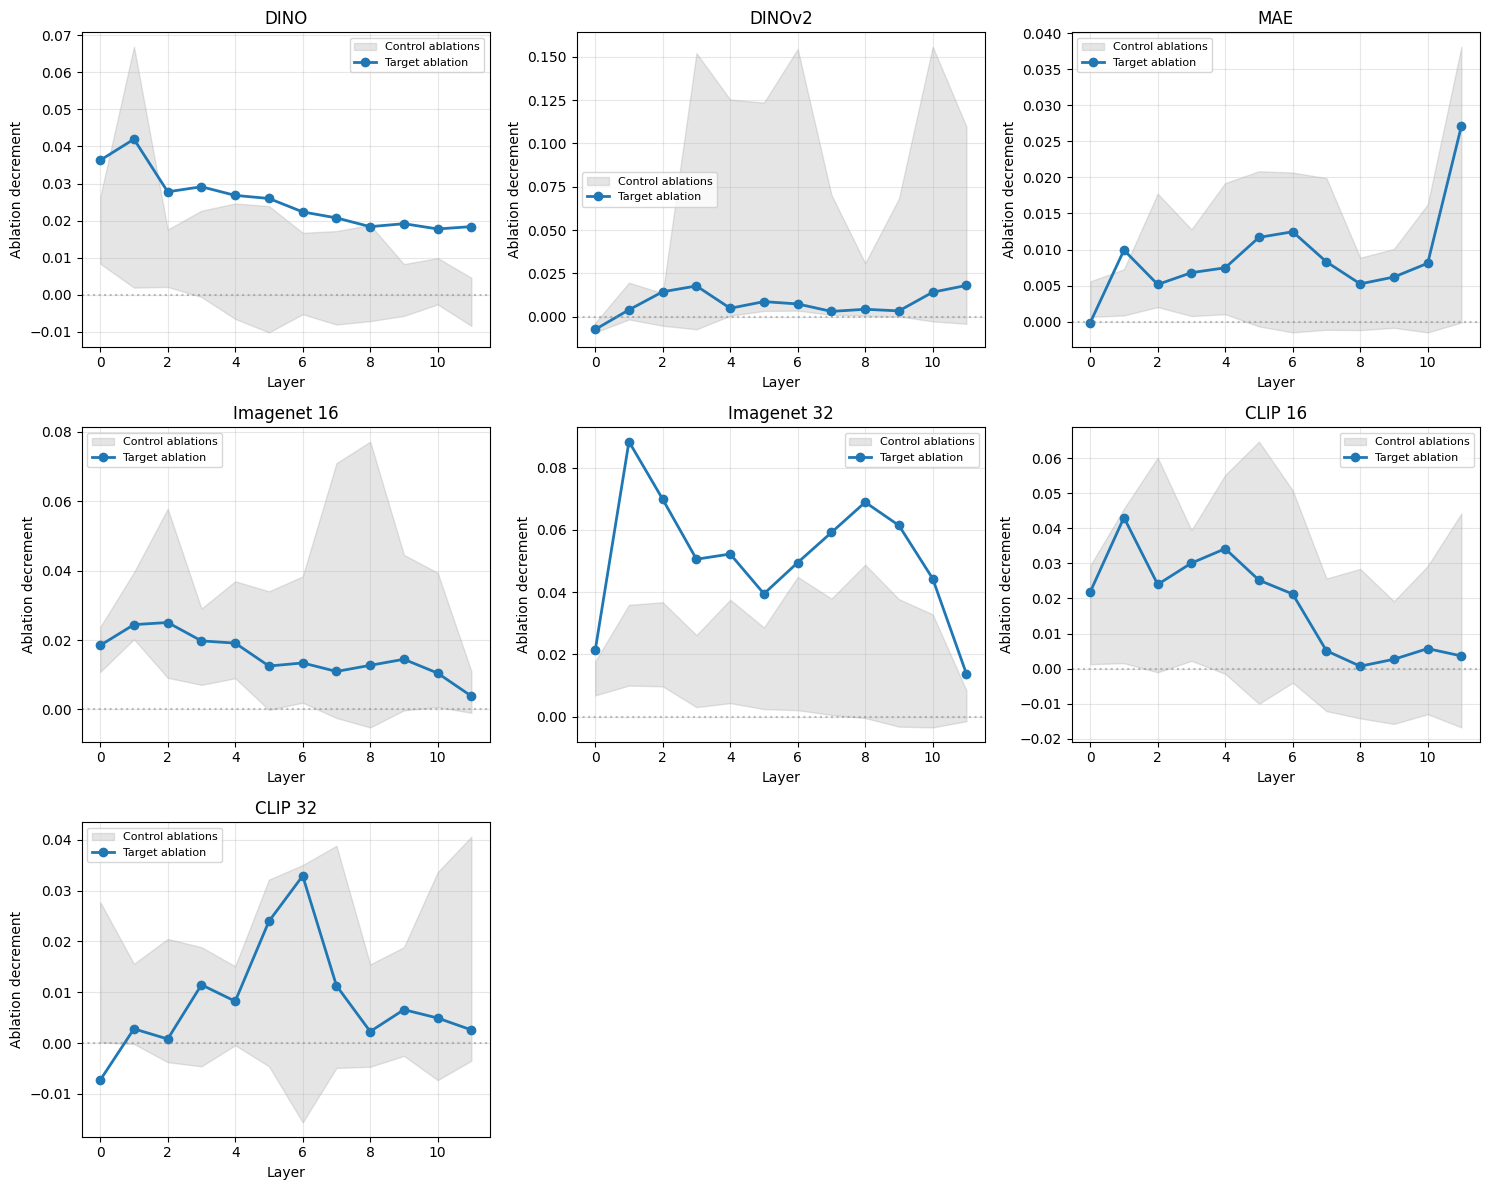

In [4]:
# Plot 2: Ablation decrement by layer (one subplot per model, dynamic control bands per layer)
plot_ablation_decrement_by_layer(data=data, control_band="minmax", normalize_by=None)
plt.show()

In [ ]:
def plot_average_scramble_delta_by_layer(data=None, results_dir=None, models=None, ax=None):
    """
    Plot per-layer delta across models, where
    delta(layer, model) = base_accuracy - max(orientation_accuracy, location_accuracy).

    Main line: mean delta across models.
    Shaded band: min-to-max delta across models at each layer.
    """
    data = data or load_gestalt_results(results_dir)
    if models:
        data = {m: data[m] for m in models if m in data}

    if not data:
        raise ValueError('No model data available for plotting.')

    deltas_by_model = {}
    all_layers = set()

    for model_name, layer_results in sorted(data.items()):
        model_deltas = {}
        for layer in sorted(layer_results.keys()):
            res = layer_results[layer]["standard"]
            base = res["base"]["accuracy"]
            orient = res["orientation"]["accuracy"]
            loc = res["location"]["accuracy"]
            model_deltas[layer] = base - max(orient, loc)
            all_layers.add(layer)
        deltas_by_model[model_name] = model_deltas

    layers = sorted(all_layers)
    delta_matrix = []
    for model_name in sorted(deltas_by_model.keys()):
        row = [deltas_by_model[model_name].get(layer, np.nan) for layer in layers]
        delta_matrix.append(row)

    delta_matrix = np.asarray(delta_matrix, dtype=float)
    mean_delta = np.nanmean(delta_matrix, axis=0)
    min_delta = np.nanmin(delta_matrix, axis=0)
    max_delta = np.nanmax(delta_matrix, axis=0)

    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 5))

    ax.fill_between(
        layers,
        min_delta,
        max_delta,
        color="#4169E1",
        alpha=0.18,
        label="Model range (min, max)",
    )
    ax.plot(layers, mean_delta, "o-", color="#4169E1", linewidth=2.5, markersize=6, label=r"Mean $\Delta$")

    def multiply_by_ten(tick_value, position):
        # tick_value is the actual data value at the tick position (e.g., 0, 20, 40)
        # position is the index of the tick
        new_value = tick_value * 100
        return f'{new_value:.1f}' # Format as a string with no decimals

    # 2. Apply the formatter to the y-axis
    # The FuncFormatter maps the original tick values to the new multiplied labels
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(multiply_by_ten))

    ax.set_xlabel("Layer")
    ax.set_ylabel(r"$\Delta$ Probe Test Accuracy")
    ax.set_title(r"$\Delta$ Probe Test Accuracy (Base $-$ Scrambled)")
    ax.grid(True, alpha=0.3)
    ax.axhline(0, color="gray", linestyle=":", alpha=0.5)
    ax.legend()

    plt.tight_layout()
    return ax


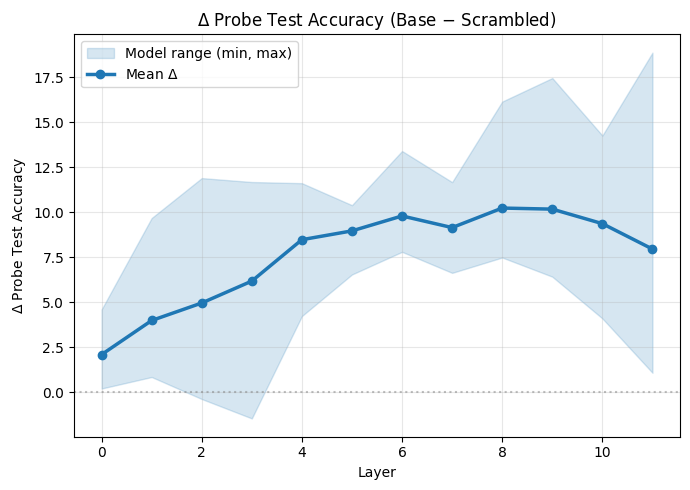

In [33]:
# Plot 3: Mean per-layer scramble delta with across-model min/max band
plot_average_scramble_delta_by_layer(data=data)
plt.show()


In [ ]:
def build_max_probe_accuracy_latex_table(data=None, results_dir=None, models=None):
    """
    Build a LaTeX table with columns:
      Model | Max Probe Test Acc. (Base, Scrambled)
    where Scrambled is max over orientation/location at each layer, then max over layers.
    """
    data = data or load_gestalt_results(results_dir)
    if models:
        data = {m: data[m] for m in models if m in data}

    if not data:
        raise ValueError('No model data available for table.')

    rows = []
    for model_name, layer_results in sorted(data.items()):
        layers = sorted(layer_results.keys())
        base_vals = [layer_results[l]["standard"]["base"]["accuracy"] for l in layers]
        scrambled_vals = [
            max(
                layer_results[l]["standard"]["orientation"]["accuracy"],
                layer_results[l]["standard"]["location"]["accuracy"],
            )
            for l in layers
        ]

        max_base = max(base_vals) * 100.0
        max_scrambled = max(scrambled_vals) * 100.0
        rows.append((simplify_model_name(model_name), max_base, max_scrambled))

    lines = []
    lines.append('\\begin{table}[t]')
    lines.append('\\centering')
    lines.append('\\begin{tabular}{lcc}')
    lines.append('\\toprule')
    lines.append('Model & \\multicolumn{2}{c}{Max Probe Test Acc.} \\\')
    lines.append(' & Base & Scrambled \\\')
    lines.append('\\midrule')

    for model_label, max_base, max_scrambled in rows:
        lines.append(f'{model_label} & {max_base:.1f}\% & {max_scrambled:.1f}\% \\\')

    lines.append('\\bottomrule')
    lines.append('\\end{tabular}')
    lines.append('\\caption{Maximum probe test accuracy by model for base and scrambled conditions.}')
    lines.append('\\label{tab:max_probe_test_acc}')
    lines.append('\\end{table}')

    return '\n'.join(lines)


In [ ]:
# Plot/Table 4: LaTeX table for max base vs scrambled probe test accuracy
latex_table = build_max_probe_accuracy_latex_table(data=data)
print(latex_table)
